# 13 - Correspondencia entre operación y perfiles de propiedades

- Pregunta: ¿las etiquetas existentes de **venta**, **alquiler permanente** y **alquiler temporal** se asocian con grupos que emergen al agrupar publicaciones por atributos de la propiedad y su entorno?
- Unidad: publicación inmobiliaria; el clustering no recibe el tipo de operación ni la fuente.
- Se fija `k=3` por las tres etiquetas preexistentes. No se pretende descubrir ni definir nuevas categorías oficiales.
- PCA representa variables numéricas comparables; K-means genera una partición no supervisada que luego se contrasta con las etiquetas.
- La asociación principal se contrasta con permutaciones de etiquetas dentro de estratos fuente × barrio que contienen más de una operación, para reducir el efecto de la composición de portales.
- Precio no entra en el espacio principal: venta (stock/precio total), alquiler (flujo mensual) y temporario tienen unidades o coberturas distintas. Se resume después, por operación y por separado.
- Insumo estable: `data/processed/df_publicaciones_enriquecidas_v1.csv`; contexto barrial: `kpis_barrio_v1.csv`.

- En cada bloque se declaran los supuestos y límites que afectan su lectura; las conclusiones quedan condicionadas a la cobertura y al corte de publicaciones disponibles.


## 1. Alcance, hipótesis y controles

- **H0:** dentro de combinaciones fuente × barrio que contienen más de una operación, la etiqueta de operación no muestra asociación con el cluster, más allá de lo esperable al permutar etiquetas conservando la composición de cada fuente y barrio.
- **H1:** la asociación observada supera ese nulo condicionado. Se reportan magnitud, tabla de composición, ARI/AMI, V de Cramér e incertidumbre descriptiva; no se interpreta como causalidad.
- Variables candidatas: ambientes, superficie y atributos físicos con cobertura suficiente; distancia a transporte/espacio verde; densidades barriales de servicios y porcentaje verde.
- Se excluyen identificadores, precio, operación, fuente y flags de calidad del espacio de clustering. La fuente se usa solo para el contraste condicionado.
- Se excluyen registros marcados como presentes en varias operaciones para evitar contar el mismo identificador con etiquetas diferentes.
- Los resultados dependen de publicaciones observadas y geocodificadas: no representan todas las viviendas ni transacciones.

- **Supuestos y salvedades:** la unidad es una publicación capturada, no un inmueble único ni una transacción. Excluir IDs marcados en más de una operación reduce duplicación etiquetada, pero no resuelve avisos distintos de una misma propiedad ni diferencias en la recolección de cada portal.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, adjusted_mutual_info_score, normalized_mutual_info_score
from src import config

REPORTS = config.REPORTS_DIR
base = pd.read_csv(config.PROCESSED_DIR / "df_publicaciones_enriquecidas_v1.csv", low_memory=False, dtype={"id_publicacion": str})
kb = pd.read_csv(config.PROCESSED_DIR / "kpis_barrio_v1.csv")

# Normalizar alias sin reclasificar operaciones cuya naturaleza no sea explícita.
op = base["tipo_operacion_norm"].astype(str).str.lower().str.strip()
alias = {
    "alquiler_temporario": "alquiler_temporal",
    "alquiler temporal": "alquiler_temporal", "temporario": "alquiler_temporal",
    "alquiler_temp": "alquiler_temporal", "temporary_rent": "alquiler_temporal",
    "alquiler_permanente": "alquiler", "alquiler permanente": "alquiler",
}
base["segmento_operacion"] = op.replace(alias)
base["segmento_operacion"] = base["segmento_operacion"].replace({"alquiler": "alquiler_permanente"})
segmentos = ["venta", "alquiler_permanente", "alquiler_temporal"]
muestra = base[base["segmento_operacion"].isin(segmentos)].copy()

# Una observación repetida entre operaciones puede hacer que el algoritmo aprenda la etiqueta duplicada.
if "id_en_multiples_operaciones_flag" in muestra:
    multi = muestra["id_en_multiples_operaciones_flag"].astype(str).str.lower().isin(["true", "1", "si", "sí"])
    muestra = muestra.loc[~multi].copy()

# Incorporar contexto por barrio si no está ya materializado en la base enriquecida.
ctx_candidatas = [c for c in kb.columns if c.startswith("densidad_") or c == "pct_superficie_verde"]
ctx_disponibles = [c for c in ctx_candidatas if c not in muestra.columns]
if ctx_disponibles:
    muestra = muestra.merge(kb[["barrio_oficial"] + ctx_disponibles], on="barrio_oficial", how="left", validate="many_to_one")

print("Publicaciones por operación antes del filtro de cobertura:")
display(muestra["segmento_operacion"].value_counts().reindex(segmentos, fill_value=0).rename("n").to_frame())
print("Fuentes:", muestra["fuente_norm"].nunique(), "| Barrios:", muestra["barrio_oficial"].nunique())


Publicaciones por operación antes del filtro de cobertura:


,n
segmento_operacion,
venta,43232
alquiler_permanente,9333
alquiler_temporal,12863


Fuentes: 4 | Barrios: 48


## 2. Selección transparente de variables y cobertura

- La cobertura se calcula por segmento antes de fijar la muestra analítica.
- Se conservan variables numéricas observadas/derivadas con al menos 60% de datos en **cada** segmento; la regla evita que la PCA represente solo un portal o una modalidad.
- Después se usa el conjunto completo de casos en esas variables. No se imputa con medias de otros segmentos.
- Los conteos, densidades, distancias y superficies se transforman con `log1p` para reducir asimetría; las variables con nombres de conteos físicos, incluido ambientes/baños, también usan log1p cuando no son negativas; porcentaje verde conserva su escala antes del estandarizado.
- La lista final debe revisarse con la tabla de cobertura: si quedan muy pocas variables o la muestra pierde demasiados casos, el resultado se informa como no evaluable y se ajusta la regla con justificación.

### Supuestos y límites de la selección

- La regla de cobertura es operativa, no demuestra que los faltantes sean aleatorios. La muestra final representa casos completos dentro de las fuentes y segmentos que superan el umbral.
- Evitar imputaciones reduce perfiles artificiales; a cambio puede cambiar la composición de la muestra. Revisar cobertura y n por segmento antes de interpretar.
- Ambientes, baños, dormitorios y superficie pueden estar reconstruidos o medidos de forma distinta por portal; son atributos publicados armonizados, no mediciones homogéneas certificadas.


In [2]:
candidatas = [
    "ambientes_ref", "dormitorios_ref", "banios_ref", "cocheras_ref", "superficie_ref_m2",
    "dist_transporte_masivo_m", "dist_espacio_verde_m", "dist_hospitales_m",
    "densidad_subte_km2", "densidad_tren_km2", "densidad_metrobus_km2",
    "densidad_educacion_km2", "densidad_hospitales_km2", "densidad_culturales_km2",
    "densidad_gastronomia_km2", "pct_superficie_verde",
]
candidatas = [c for c in candidatas if c in muestra.columns]
cobertura = muestra.groupby("segmento_operacion")[candidatas].apply(lambda x: x.notna().mean()).T
cobertura.columns.name = "segmento_operacion"
display((100 * cobertura).round(1).rename_axis("variable").reset_index())
min_cobertura = 0.60
features = [c for c in candidatas if (cobertura.loc[c] >= min_cobertura).all()]
print("Variables que cumplen cobertura mínima:", features)
assert len(features) >= 3, "No hay 3 variables con cobertura suficiente; revisar cobertura/alcance antes del clustering."

analisis = muestra.dropna(subset=features + ["fuente_norm", "segmento_operacion"]).copy()
print("Casos completos:", len(analisis), "de", len(muestra), "({:.1f}%)".format(100 * len(analisis) / max(1, len(muestra))))
display(analisis.groupby("segmento_operacion").size().reindex(segmentos, fill_value=0).rename("n_completo").to_frame())
assert analisis["segmento_operacion"].nunique() == 3, "La muestra completa no contiene las tres operaciones."

X = analisis[features].apply(pd.to_numeric, errors="coerce")
assert X.notna().all().all(), "La selección de casos completos debe preceder al escalado."
cols_log = [c for c in features if any(t in c for t in ["superficie", "dist_", "densidad_", "cocheras", "dormitorios", "banios", "ambientes"])]
for c in cols_log:
    if X[c].min() >= 0:
        X[c] = np.log1p(X[c])
Xz = StandardScaler().fit_transform(X)
y = analisis["segmento_operacion"].to_numpy()
print("Dimensión de la matriz estandarizada:", Xz.shape)


segmento_operacion,variable,alquiler_permanente,alquiler_temporal,venta
0,ambientes_ref,97.2,98.9,98.9
1,dormitorios_ref,5.2,74.6,1.4
2,banios_ref,97.8,99.5,97.6
3,superficie_ref_m2,99.5,25.3,99.9
4,dist_transporte_masivo_m,80.9,94.0,86.2
5,dist_espacio_verde_m,80.9,94.0,86.2
6,dist_hospitales_m,80.9,94.0,86.2
7,densidad_subte_km2,99.8,99.2,99.8
8,densidad_tren_km2,99.8,99.2,99.8
9,densidad_metrobus_km2,99.8,99.2,99.8


Variables que cumplen cobertura mínima: ['ambientes_ref', 'banios_ref', 'dist_transporte_masivo_m', 'dist_espacio_verde_m', 'dist_hospitales_m', 'densidad_subte_km2', 'densidad_tren_km2', 'densidad_metrobus_km2', 'densidad_educacion_km2', 'densidad_hospitales_km2', 'densidad_culturales_km2', 'densidad_gastronomia_km2', 'pct_superficie_verde']
Casos completos: 55158 de 65428 (84.3%)


,n_completo
segmento_operacion,
venta,36071
alquiler_permanente,7153
alquiler_temporal,11934


Dimensión de la matriz estandarizada: (55158, 13)


## 3. PCA y lectura de los ejes

- PCA se ajusta sobre las publicaciones completas usando solo las variables seleccionadas, sin etiquetas ni precio.
- Se conserva el menor número de componentes que alcanza 80% de varianza explicada, con máximo de 8; K-means trabaja sobre esos componentes.
- La varianza y las cargas describen el espacio; no convierten los ejes en dimensiones habitacionales oficiales.

### Supuestos y límites de PCA

- PCA resume asociaciones lineales en variables estandarizadas y transformadas; los componentes dependen de la selección de variables y pueden cambiar ante otra regla de cobertura.
- La varianza explicada no prueba que los ejes sean útiles para clasificar operaciones. Componentes ortogonales son una propiedad matemática, no dimensiones sociales independientes.


,componente,varianza_explicada,varianza_acumulada
0,PC1,0.238,0.238
1,PC2,0.174,0.412
2,PC3,0.127,0.539
3,PC4,0.110,0.649
4,PC5,0.074,0.723
5,PC6,0.063,0.786
6,PC7,0.059,0.845
7,PC8,0.048,0.893
8,PC9,0.033,0.927
9,PC10,0.029,0.956


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
ambientes_ref,-0.071,0.013,0.597,-0.374,0.029,-0.092,-0.022
banios_ref,-0.104,-0.035,0.604,-0.333,0.085,-0.012,0.063
dist_transporte_masivo_m,-0.211,0.171,0.115,0.197,0.453,0.648,-0.444
dist_espacio_verde_m,0.033,0.194,-0.234,-0.263,0.673,-0.025,0.592
dist_hospitales_m,-0.013,-0.482,-0.106,-0.143,0.280,0.003,-0.079
densidad_subte_km2,0.495,0.013,0.079,0.015,0.071,0.021,-0.124
densidad_tren_km2,-0.185,-0.151,-0.151,-0.353,-0.389,0.664,0.304
densidad_metrobus_km2,0.208,-0.415,-0.102,-0.228,-0.093,-0.011,-0.108
densidad_educacion_km2,0.305,0.315,-0.146,-0.383,-0.160,0.160,-0.067
densidad_hospitales_km2,0.047,0.504,0.170,0.215,-0.239,0.050,0.277


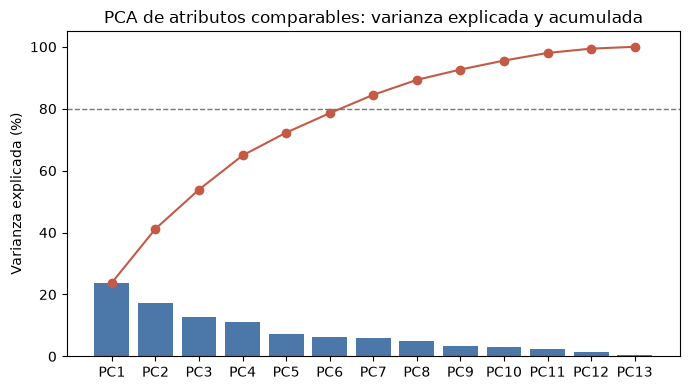

In [3]:
pca = PCA().fit(Xz)
coord = pca.transform(Xz)
varianza = pd.DataFrame({"componente": ["PC{}".format(i + 1) for i in range(len(pca.explained_variance_ratio_))],
                         "varianza_explicada": pca.explained_variance_ratio_,
                         "varianza_acumulada": np.cumsum(pca.explained_variance_ratio_)})
n_pc = min(int(np.searchsorted(varianza["varianza_acumulada"].to_numpy(), .80) + 1), 8, coord.shape[1])
Z = coord[:, :n_pc]
cargas = pd.DataFrame(pca.components_[:n_pc].T, index=features,
                      columns=["PC{}".format(i + 1) for i in range(n_pc)])
display(varianza.round(3))
display(cargas.round(3))
varianza.to_csv(REPORTS / "pe3_pca_operaciones_varianza_v1.csv", index=False)
cargas.to_csv(REPORTS / "pe3_pca_operaciones_cargas_v1.csv")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(varianza["componente"], 100 * varianza["varianza_explicada"], color="#4b78a8")
ax.plot(varianza["componente"], 100 * varianza["varianza_acumulada"], color="#c45a46", marker="o")
ax.axhline(80, color="#777", linestyle="--", linewidth=1)
ax.set_ylabel("Varianza explicada (%)")
ax.set_title("PCA de atributos comparables: varianza explicada y acumulada")
plt.tight_layout(); plt.show()


## 4. Clustering no supervisado con k=3

- `k=3` se define por la cantidad de etiquetas existentes, no por maximizar su coincidencia.
- La silueta se informa para k=2–6 como diagnóstico geométrico, sin seleccionar k por su alineación con operación.
- Se valida estabilidad del K-means de k=3 mediante 30 submuestras del 80% y ARI contra la asignación base en los casos compartidos.
- Una asociación alta no implica que las operaciones sean categorías naturales de vivienda: puede reflejar variables de publicación, cobertura o geografía.

### Supuestos y límites de K-means

- K-means usa distancia euclídea y favorece grupos compactos, comparables en escala y aproximadamente convexos. Puede ser sensible a inicialización, valores extremos y al predominio de atributos repetidos por barrio.
- Fijar k=3 responde a la comparación con tres etiquetas existentes; no demuestra que haya tres grupos naturales. Silueta y ARI de submuestras son diagnósticos complementarios, no validación sustantiva.
- Los registros del mismo barrio comparten indicadores contextuales. La prueba posterior conserva composición por fuente y barrio, pero la partición sigue describiendo esta muestra de avisos.


,k,silueta_muestra
0,2,0.212
1,3,0.223
2,4,0.217
3,5,0.240
4,6,0.238


ARI de estabilidad, mediana: 0.997 | rango intercuartílico: (np.float64(0.995), np.float64(0.998))


,venta,alquiler_permanente,alquiler_temporal,publicaciones
cluster_propiedad,,,,
1,54.9,11.4,33.7,4495
2,66.1,14.0,19.9,16527
3,66.4,12.7,20.9,34136


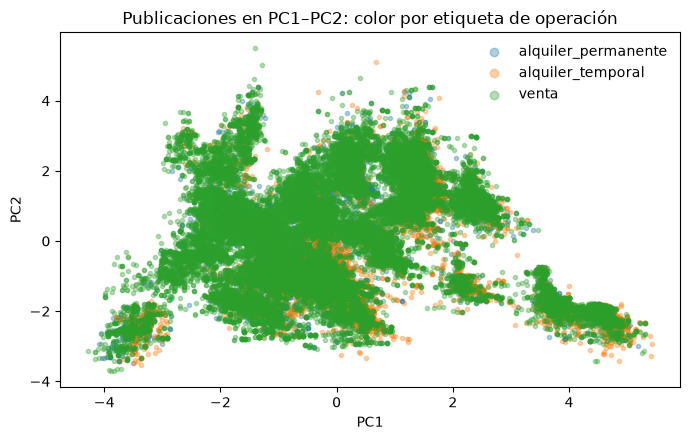

In [4]:
rng = np.random.default_rng(2026)
n = len(Z)
sample_sil = min(4000, n)
validacion_interna = []
modelos = {}
for k in range(2, min(6, n - 1) + 1):
    km = KMeans(n_clusters=k, n_init=30, random_state=2026).fit(Z)
    modelos[k] = km
    sil = silhouette_score(Z, km.labels_, sample_size=sample_sil, random_state=2026) if n > sample_sil else silhouette_score(Z, km.labels_)
    validacion_interna.append({"k": k, "silueta_muestra": sil})
validacion_interna = pd.DataFrame(validacion_interna)
display(validacion_interna.round(3))

k = 3
modelo = modelos[k]
cluster = modelo.labels_ + 1
analisis["cluster_propiedad"] = cluster
ari_estabilidad = []
for rep in range(30):
    idx = np.sort(rng.choice(n, size=max(k + 2, int(.8 * n)), replace=False))
    sub = KMeans(n_clusters=k, n_init=20, random_state=rep).fit_predict(Z[idx])
    ari_estabilidad.append(adjusted_rand_score(cluster[idx], sub))
estabilidad = pd.Series(ari_estabilidad)
print("ARI de estabilidad, mediana:", round(estabilidad.median(), 3),
      "| rango intercuartílico:", tuple(np.round(estabilidad.quantile([.25, .75]).to_numpy(), 3)))

var_label = pd.crosstab(analisis["cluster_propiedad"], analisis["segmento_operacion"], normalize="index").reindex(columns=segmentos, fill_value=0) * 100
n_cluster = analisis["cluster_propiedad"].value_counts().sort_index().rename("publicaciones")
composicion = var_label.join(n_cluster)
display(composicion.round(1))
composicion.to_csv(REPORTS / "pe3_clusters_propiedades_composicion_v1.csv")
validacion_interna.to_csv(REPORTS / "pe3_clusters_propiedades_silueta_v1.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
for op_label, grupo in analisis.groupby("segmento_operacion"):
    ix = grupo.index
    loc = analisis.index.get_indexer(ix)
    ax.scatter(coord[loc, 0], coord[loc, 1], s=9, alpha=.35, label=op_label)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Publicaciones en PC1–PC2: color por etiqueta de operación")
ax.legend(frameon=False, markerscale=2)
plt.tight_layout(); plt.show()


## 5. Contraste de correspondencia con las etiquetas

- ARI y AMI comparan la partición con las tres etiquetas; V de Cramér resume asociación en la tabla cluster × operación.
- La prueba de permutación mantiene fijos los clusters y permuta etiquetas **dentro de cada fuente × barrio**, en los estratos que tienen dos o más operaciones observadas. Así se pregunta si la correspondencia se sostiene dentro de portales con variación real de operación.
- Fuentes con una sola operación no identifican asociación condicionada y quedan fuera de este contraste, aunque sí aparecen en los resultados descriptivos generales.
- El p-valor de permutación se acompaña de efecto observado; no se toma significancia como evidencia de importancia práctica.

### Supuestos y límites de la permutación

- El nulo requiere que, dentro de cada estrato fuente × barrio con varias operaciones, las etiquetas sean intercambiables bajo ausencia de asociación residual. No corrige diferencias de fecha, geocodificación, perfil de vendedor, selección de avisos ni medición de atributos.
- La prueba condicionada solo habla de los estratos con solapamiento de modalidades; si quedan pocos barrios o no hay casos temporarios en ellos, no permite generalizar a todas las publicaciones.
- Puede persistir dependencia entre avisos de una inmobiliaria o una propiedad. El p-valor es una referencia de aleatorización condicionada, no un intervalo de confianza poblacional; se priorizan tamaño, composición y estabilidad.


In [5]:
def cramers_v(tabla):
    obs = tabla.to_numpy(dtype=float)
    total = obs.sum()
    if total == 0 or min(obs.shape) < 2:
        return np.nan
    esperado = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / total
    chi2 = np.nansum((obs - esperado) ** 2 / np.where(esperado == 0, np.nan, esperado))
    phi2 = chi2 / total
    r, c = obs.shape
    phi2_corr = max(0, phi2 - ((c - 1) * (r - 1)) / max(total - 1, 1))
    r_corr = r - ((r - 1) ** 2) / max(total - 1, 1)
    c_corr = c - ((c - 1) ** 2) / max(total - 1, 1)
    return np.sqrt(phi2_corr / max(min(c_corr - 1, r_corr - 1), 1e-12))

rng_perm = np.random.default_rng(917)

tabla = pd.crosstab(analisis["cluster_propiedad"], analisis["segmento_operacion"]).reindex(columns=segmentos, fill_value=0)
v_observada = cramers_v(tabla)
ari_observado = adjusted_rand_score(y, cluster)
ami_observado = adjusted_mutual_info_score(y, cluster)
print("Muestra completa | ARI:", round(ari_observado, 4), "| AMI:", round(ami_observado, 4), "| V de Cramér:", round(v_observada, 4))

# Prueba principal: permutación dentro de fuente × barrio en estratos con varias operaciones.
estrato = (analisis["fuente_norm"].astype(str) + "¦" +
           analisis["barrio_oficial"].fillna("sin_barrio").astype(str)).to_numpy()
grupos = pd.Series(np.arange(len(estrato))).groupby(pd.Series(estrato), sort=False).indices.values()
estratos = [ix for ix in grupos if np.unique(y[ix]).size >= 2]
mask_estrato = np.zeros(len(analisis), dtype=bool)
for ix in estratos:
    mask_estrato[ix] = True
print("Estratos fuente × barrio con más de una operación:", len(estratos))
print("Casos en la prueba principal:", int(mask_estrato.sum()), "de", len(analisis))
if mask_estrato.sum() == 0:
    print("No hay solapamiento suficiente para una prueba condicionada por fuente y barrio.")
    ami_estrato, p_estrato, ami_null_estrato = np.nan, np.nan, np.array([])
else:
    y_estrato, cl_estrato = y[mask_estrato], cluster[mask_estrato]
    ami_estrato = adjusted_mutual_info_score(y_estrato, cl_estrato)
    estrato_sub = estrato[mask_estrato]
    ix_estratos_sub = pd.Series(np.arange(len(estrato_sub))).groupby(pd.Series(estrato_sub), sort=False).indices.values()
    rng_perm = np.random.default_rng(917)
    n_perm = 499
    ami_null_estrato = np.empty(n_perm)
    for b in range(n_perm):
        y_perm = y_estrato.copy()
        for ix in ix_estratos_sub:
            y_perm[ix] = rng_perm.permutation(y_perm[ix])
        ami_null_estrato[b] = adjusted_mutual_info_score(y_perm, cl_estrato)
    p_estrato = (1 + np.sum(ami_null_estrato >= ami_estrato)) / (n_perm + 1)

# Sensibilidad: la permutación solo por fuente conserva menos estructura geográfica.
fuente = analisis["fuente_norm"].astype(str).to_numpy()
ix_fuentes = pd.Series(np.arange(len(fuente))).groupby(pd.Series(fuente), sort=False).indices.values()
fuentes_multi = [ix for ix in ix_fuentes if np.unique(y[ix]).size >= 2]
mask_fuente = np.zeros(len(analisis), dtype=bool)
for ix in fuentes_multi:
    mask_fuente[ix] = True
if mask_fuente.sum():
    y_fuente, cl_fuente = y[mask_fuente], cluster[mask_fuente]
    ami_fuente = adjusted_mutual_info_score(y_fuente, cl_fuente)
    fuente_sub = fuente[mask_fuente]
    ix_fuente_sub = pd.Series(np.arange(len(fuente_sub))).groupby(pd.Series(fuente_sub), sort=False).indices.values()
    ami_null_fuente = np.empty(499)
    for b in range(499):
        y_perm = y_fuente.copy()
        for ix in ix_fuente_sub:
            y_perm[ix] = rng_perm.permutation(y_perm[ix])
        ami_null_fuente[b] = adjusted_mutual_info_score(y_perm, cl_fuente)
    p_fuente = (1 + np.sum(ami_null_fuente >= ami_fuente)) / 500
else:
    ami_fuente, p_fuente = np.nan, np.nan

res_contraste = pd.DataFrame([{
    "n_completo": len(analisis), "n_fuente_barrio_comparables": int(mask_estrato.sum()),
    "estratos_fuente_barrio_con_solapamiento": len(estratos),
    "ari_total": ari_observado, "ami_total": ami_observado, "cramers_v_total": v_observada,
    "ami_fuente_barrio": ami_estrato,
    "ami_perm_media_fuente_barrio": float(ami_null_estrato.mean()) if len(ami_null_estrato) else np.nan,
    "ami_perm_p95_fuente_barrio": float(np.quantile(ami_null_estrato, .95)) if len(ami_null_estrato) else np.nan,
    "p_permutacion_fuente_barrio": p_estrato,
    "n_fuentes_comparables": int(mask_fuente.sum()), "ami_fuente": ami_fuente,
    "p_permutacion_fuente": p_fuente, "permutaciones": 499
}])
display(res_contraste.round(4))
res_contraste.to_csv(REPORTS / "pe3_validacion_etiquetas_operacion_v1.csv", index=False)

Muestra completa | ARI: 0.0151 | AMI: 0.0041 | V de Cramér: 0.0628
Estratos fuente × barrio con más de una operación: 52
Casos en la prueba principal: 45628 de 55158


,n_completo,n_fuente_barrio_comparables,estratos_fuente_barrio_con_solapamiento,ari_total,ami_total,cramers_v_total,ami_fuente_barrio,ami_perm_media_fuente_barrio,ami_perm_p95_fuente_barrio,p_permutacion_fuente_barrio,n_fuentes_comparables,ami_fuente,p_permutacion_fuente,permutaciones
0,55158,45628,52,0.0151,0.0041,0.0628,0.0012,0.0012,0.0012,0.25,45646,0.0012,0.002,499


## 6. Perfil de los grupos y lectura para el caso de negocio

- Se informa la mezcla de operaciones por cluster y la mediana de los atributos que lo definen.
- Precio se incorpora **solo para describir** los grupos ya formados, en tablas separadas por tipo de operación: precio total de venta, precio mensual de alquiler y precio por m² cuando exista. No se interpretan como una escala común.
- Una correspondencia alta indicaría que parte de las diferencias entre mercados publicados está alineada con atributos físicos/urbanos. Una correspondencia baja indicaría que las etiquetas representan modalidades que comparten perfiles o que las variables disponibles no las distinguen.
- La segmentación no demuestra desplazamiento entre alquiler temporal y permanente, demanda insatisfecha, déficit habitacional ni causalidad. Sirve para decidir qué diferencias merecen validación adicional en los indicadores de oferta, accesibilidad y concentración definidos para el Instituto.

### Supuestos y límites de los perfiles

- Las medianas describen los anuncios que componen cada grupo; no representan valores transados ni corrigen la selección de cada portal.
- El precio es suplementario: diferencias observadas por cluster no participaron de su definición y no son efectos atribuibles al grupo.


In [6]:
perfil_vars = [c for c in features if c in analisis.columns]
perfil = analisis.groupby("cluster_propiedad")[perfil_vars].median().round(3)
perfil.insert(0, "n_publicaciones", analisis.groupby("cluster_propiedad").size())
display(perfil)
perfil.to_csv(REPORTS / "pe3_perfiles_clusters_propiedades_v1.csv")

# Precio como variable suplementaria: resumir por operación sin mezclar unidades.
precios = [c for c in ["precio_venta_usd", "precio_mensual_usd", "precio_m2_usd"] if c in analisis.columns]
if precios:
    filas_precio = []
    for (op_label, cl), grupo in analisis.groupby(["segmento_operacion", "cluster_propiedad"]):
        for variable in precios:
            s = pd.to_numeric(grupo[variable], errors="coerce").dropna()
            if len(s):
                filas_precio.append({"operacion": op_label, "cluster": cl, "variable_precio": variable,
                                     "n": len(s), "mediana": s.median(), "p25": s.quantile(.25), "p75": s.quantile(.75)})
    resumen_precio = pd.DataFrame(filas_precio)
    display(resumen_precio.round(2))
    resumen_precio.to_csv(REPORTS / "pe3_perfil_precios_por_operacion_cluster_v1.csv", index=False)

salida = analisis[["id_publicacion", "fuente_norm", "barrio_oficial", "segmento_operacion", "cluster_propiedad"] + features].copy()
salida.to_csv(config.PROCESSED_DIR / "pe3_clusters_publicaciones_operacion_v1.csv", index=False)


,n_publicaciones,ambientes_ref,banios_ref,dist_transporte_masivo_m,dist_espacio_verde_m,dist_hospitales_m,densidad_subte_km2,densidad_tren_km2,densidad_metrobus_km2,densidad_educacion_km2,densidad_hospitales_km2,densidad_culturales_km2,densidad_gastronomia_km2,pct_superficie_verde
cluster_propiedad,,,,,,,,,,,,,,
1,4495,2.0,1.0,200.338,247.285,1719.892,4.093,0.000,18.193,9.611,0.000,111.888,67.770,2.511
2,16527,2.0,1.0,375.980,315.034,704.299,1.088,0.146,0.000,11.969,0.466,36.536,18.245,1.549
3,34136,2.0,1.0,396.829,279.285,1436.502,0.277,0.277,1.093,7.561,0.000,11.792,8.809,2.079


,operacion,cluster,variable_precio,n,mediana,p25,p75
0,alquiler_permanente,1,precio_mensual_usd,514,545.44,414.67,876.88
1,alquiler_permanente,1,precio_m2_usd,512,12.88,10.58,18.89
2,alquiler_permanente,2,precio_mensual_usd,2311,524.49,426.15,819.51
3,alquiler_permanente,2,precio_m2_usd,2304,13.03,10.93,15.61
4,alquiler_permanente,3,precio_mensual_usd,4328,642.50,458.93,1081.75
5,alquiler_permanente,3,precio_m2_usd,4306,14.75,12.21,18.82
6,alquiler_temporal,1,precio_mensual_usd,1514,1435.00,1049.25,2195.75
7,alquiler_temporal,2,precio_mensual_usd,3295,1500.00,1099.00,2166.00
8,alquiler_temporal,3,precio_mensual_usd,7125,1758.00,1257.00,2686.00
9,venta,1,precio_venta_usd,2467,99000.00,72000.00,145600.00


## 7. Criterios para cerrar la interpretación

- Reportar la composición de cada cluster con denominadores y tamaños; revisar clusters dominados por una fuente o barrio.
- Considerar la estabilidad por submuestras y la diferencia entre AMI total y AMI condicionado por fuente.
- Si la permutación condicionada no respalda asociación, no sostener que los segmentos se recuperan naturalmente.
- Si la asociación aparece solo en el contraste total pero desaparece al condicionar por fuente, atribuirla como posible efecto de cobertura/composición del portal.
- Aunque la asociación sea robusta, describirla como correspondencia de perfiles observados y no como explicación causal de la elección de modalidad.
- Antes de la entrega final, ejecutar este notebook después del 12, revisar las variables seleccionadas/cobertura y conservar outputs visibles.

### Supuestos y límites para la decisión

- Alineación entre etiqueta y cluster no significa que el tipo de operación sea explicado por una necesidad habitacional ni que una modalidad desplace a otra.
- La evidencia informa si los anuncios capturados se ordenan de forma parecida en este espacio de atributos; debe leerse junto con KPIs territoriales, censales y de oferta permanente.
- Si falla la cobertura o el soporte común por fuente × barrio, se reporta la limitación y no se reemplaza por una conclusión basada solo en significancia global.


## Panel visual de síntesis: ¿cuánto coinciden perfiles y etiquetas?
Las tarjetas combinan magnitud de asociación y prueba condicionada. El gráfico de composición muestra qué proporción de publicaciones de cada cluster pertenece a cada operación, con el tamaño de grupo. Si la asociación total cae al condicionar por fuente y barrio, parte de la coincidencia puede venir de cómo publican/capturan los portales en cada zona.

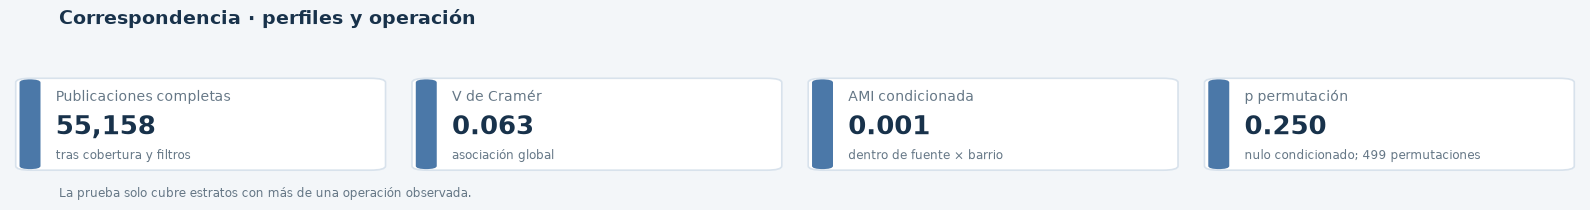

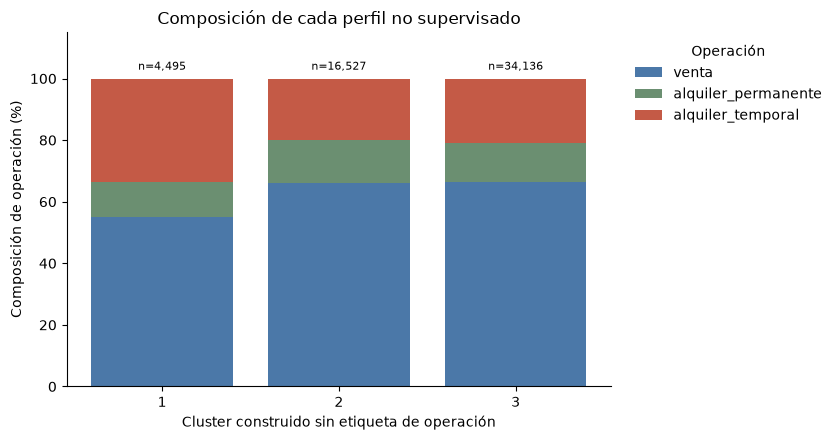

In [7]:
from src.pe3_visuals import kpi_cards
p_txt = f"{p_estrato:.3f}" if pd.notna(p_estrato) else "no estimable"
ami_txt = f"{ami_estrato:.3f}" if pd.notna(ami_estrato) else "no estimable"
kpi_cards([
 ("Publicaciones completas", f"{len(analisis):,}", "tras cobertura y filtros"),
 ("V de Cramér", f"{v_observada:.3f}", "asociación global"),
 ("AMI condicionada", ami_txt, "dentro de fuente × barrio"),
 ("p permutación", p_txt, "nulo condicionado; 499 permutaciones"),
], title="Correspondencia · perfiles y operación",
note="La prueba solo cubre estratos con más de una operación observada.")
prop = tabla.div(tabla.sum(axis=1).replace(0,np.nan),axis=0).fillna(0)*100
fig, ax = plt.subplots(figsize=(8.5,4.5))
colors=["#4b78a8","#6b8f71","#c45a46"]
bottom=np.zeros(len(prop))
for i,col in enumerate(prop.columns):
    vals=prop[col].to_numpy()
    ax.bar(prop.index.astype(str),vals,bottom=bottom,label=str(col),color=colors[i%len(colors)])
    bottom += vals
for i,n_i in enumerate(tabla.sum(axis=1)):
    ax.text(i,102,f"n={int(n_i):,}",ha="center",va="bottom",fontsize=8)
ax.set_ylim(0,115); ax.set_ylabel("Composición de operación (%)")
ax.set_xlabel("Cluster construido sin etiqueta de operación")
ax.set_title("Composición de cada perfil no supervisado")
ax.legend(title="Operación",frameon=False,bbox_to_anchor=(1.02,1),loc="upper left")
for spine in ("top","right"): ax.spines[spine].set_visible(False)
plt.tight_layout(); plt.show()

**Lectura.** La composición describe correspondencia, no “tipos naturales” de vivienda. La evidencia más exigente es la permutación dentro de fuente × barrio; también revisar el tamaño de los estratos incluidos y la sensibilidad por fuente.

## Interpretación del contraste condicionado

**Resultado.** Las publicaciones agrupadas por sus atributos físicos y su entorno casi no coinciden con la etiqueta de operación: ARI = 0,015, AMI = 0,004 y V de Cramér = 0,063 en los 55.158 casos completos. Al condicionar por fuente y barrio (45.628 casos en 52 estratos con más de una operación), la AMI observada (0,0012) es igual a la media del nulo por permutación (0,0012), con exceso de 0,000 (p = 0,25; 499 permutaciones). No hay correspondencia detectable entre los grupos y las operaciones más allá de la composición por fuente y barrio.

**Sensibilidad.** Condicionando solo por fuente, el p baja a 0,002 con la misma AMI (0,0012): la diferencia con el nulo es detectable pero sin importancia práctica.

**Por qué el ARI de estabilidad (0,997) engaña.** Las densidades de servicios son constantes dentro de cada barrio, por lo que los grupos reproducen agrupaciones de barrios y se mantienen al remuestrear. Eso muestra estabilidad geográfica, no correspondencia con la operación. La silueta (0,22) indica separación débil.

**Composición.** El cluster 1 (alta densidad de subte, cultura y gastronomía; 4.495 publicaciones) tiene 33,7 % de alquileres temporales frente a 19,9–20,9 % en los otros dos, y la venta baja de 66 % a 55 %. Esa diferencia refleja dónde se concentran los avisos de Airbnb (las 9.512 publicaciones de Airbnb de la muestra son temporales), no atributos de las propiedades.

**Alcance.** La prueba condicionada cubre casi solo a Mercado Libre: Airbnb publica una sola operación y queda fuera. La conclusión vale para ese portal.

**Para el caso de negocio.** Las etiquetas de operación no se recuperan de los atributos observados; las diferencias entre modalidades son más territoriales y de portal que de tipo de vivienda. Los resultados no apoyan hablar de «tipos de vivienda» propios de cada modalidad, ni de que una modalidad sustituya a otra.

Casos completos: **55,158**; comparables fuente×barrio: **45,628** en **52 estratos**. AMI total=0.0041; AMI comparable=0.0012; media nula condicionada=0.0012; p=0.2500. La significancia no cuantifica utilidad y el soporte común limita la generalización.

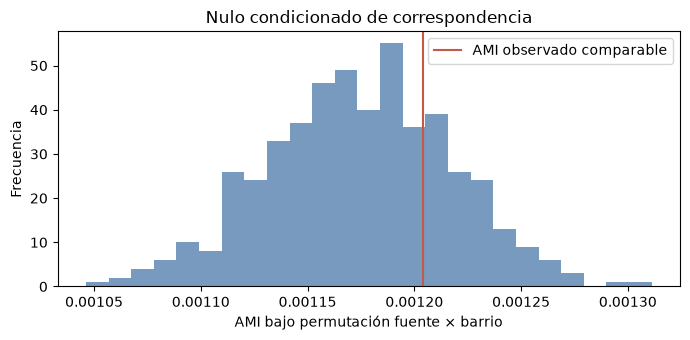

Exceso AMI sobre media nula: 0.0


In [8]:
from IPython.display import Markdown
r=res_contraste.iloc[0]
display(Markdown(f"Casos completos: **{int(r.n_completo):,}**; comparables fuente×barrio: "
 f"**{int(r.n_fuente_barrio_comparables):,}** en **{int(r.estratos_fuente_barrio_con_solapamiento)} estratos**. "
 f"AMI total={r.ami_total:.4f}; AMI comparable={r.ami_fuente_barrio:.4f}; "
 f"media nula condicionada={r.ami_perm_media_fuente_barrio:.4f}; p={r.p_permutacion_fuente_barrio:.4f}. "
 'La significancia no cuantifica utilidad y el soporte común limita la generalización.'))
if len(ami_null_estrato):
    fig,ax=plt.subplots(figsize=(7,3.5))
    ax.hist(ami_null_estrato,bins=25,color='#4b78a8',alpha=.75)
    ax.axvline(ami_estrato,color='#c45a46',label='AMI observado comparable')
    ax.set(xlabel='AMI bajo permutación fuente × barrio',ylabel='Frecuencia',title='Nulo condicionado de correspondencia')
    ax.legend();plt.tight_layout();plt.show()
    print('Exceso AMI sobre media nula:',round(ami_estrato-ami_null_estrato.mean(),4))